# 8. Benchmark metrics

In this notebook, we measure the runs of notebook 7: one violin per planner and
per metric, then the table, then the time a solve takes on this machine.

Notebook 7 has to have run: it writes the statistics of our own paths in
`runs/`, and this one reads them rather than solving again. Those paths are
solved at $k_1 = 2$, $k_2 = 3$, cleaned of the extraction chatter and closed on
the start pose.

**Summary**

1. [Metrics](#1)
2. [The table](#2)
3. [Solve time and grid size](#3)

In [1]:
import sys, os, time, logging
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from shfm import benchmark as B, metrics as M, plates as PL
from shfm.figures import FIGURE_DIR

STATS_DIR = os.path.join(os.path.abspath(".."), "runs")
os.makedirs(FIGURE_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})
logging.getLogger("fontTools").setLevel(logging.ERROR)   # font notices of the PDF plates

SCENES = ("two_rooms", "warehouse", "procedural")

RESULTS = {}
for name in SCENES:
    path = os.path.join(STATS_DIR, "stats_%s.json" % name)
    if not os.path.exists(path):
        raise SystemExit("%s missing: run notebook 7 first." % os.path.relpath(path))
    RESULTS[name] = dict(stats=PL.load_stats(path),
                         data=B.load_campaign(name),
                         file=B.campaign_file(name))
print("read", ", ".join(SCENES))

read two_rooms, warehouse, procedural


<a id='1'></a>
## 1. Metrics

We draw one violin per planner and per metric, then the summary plate of the
thesis: length, AOL, maximum curvature and minimum clearing, with the AHE, the
Approach Heading Error, centred below them. The sampling planners are read
from the statistics stored in the campaign files, every run counted. Their
normalised curvature is left out here: the stored value carries an error of the
build of Bench-MR the campaigns were run with (`external/NOTICE.md`). The table
below measures it again on the trajectories. The campaign files do not hold
the AHE either: it is measured on the trajectories of the runs that reached the
goal, over the vehicle length, so the plates need the zoom of each scene.
Unlike the table of section 2, the violins of the other metrics include the
runs that did not reach the goal.

Saved ../figures/08_two_rooms_path_length.pdf.
Saved ../figures/08_two_rooms_path_length_nolegend.pdf.


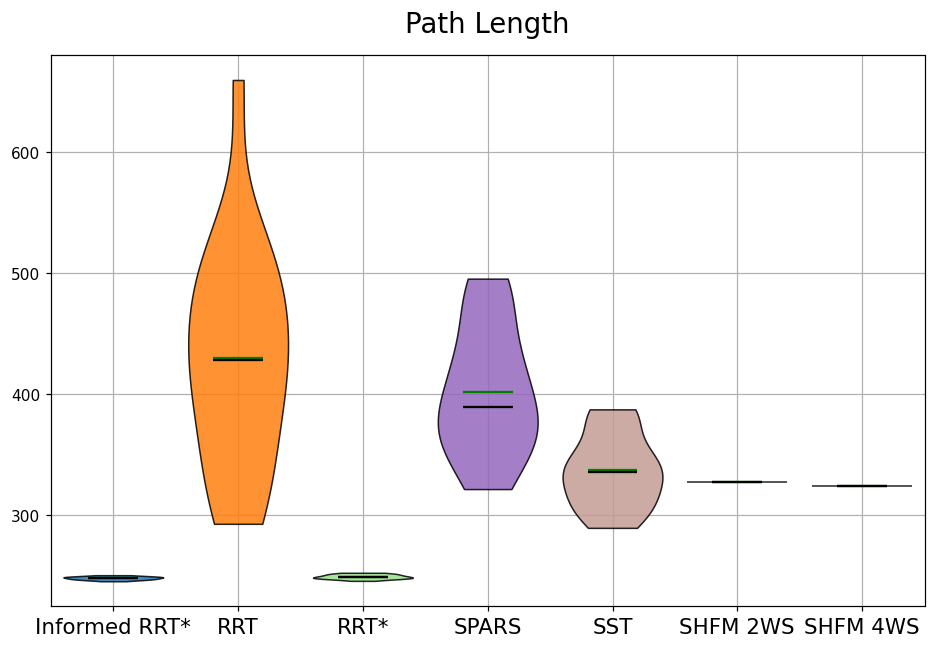

Saved ../figures/08_two_rooms_min_clearing_distance.pdf.
Saved ../figures/08_two_rooms_min_clearing_distance_nolegend.pdf.


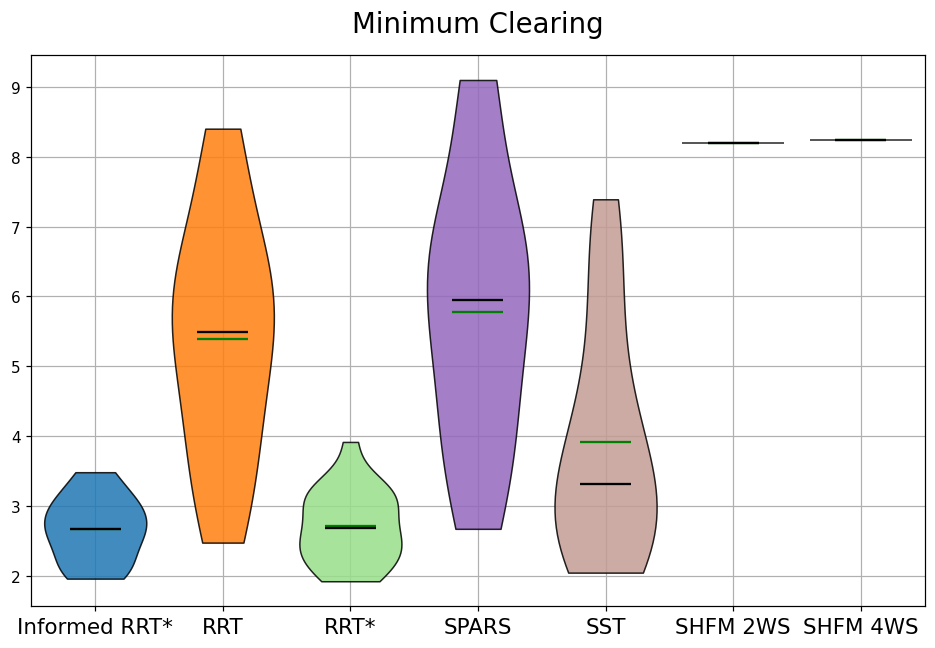

Saved ../figures/08_two_rooms_mean_clearing_distance.pdf.
Saved ../figures/08_two_rooms_mean_clearing_distance_nolegend.pdf.


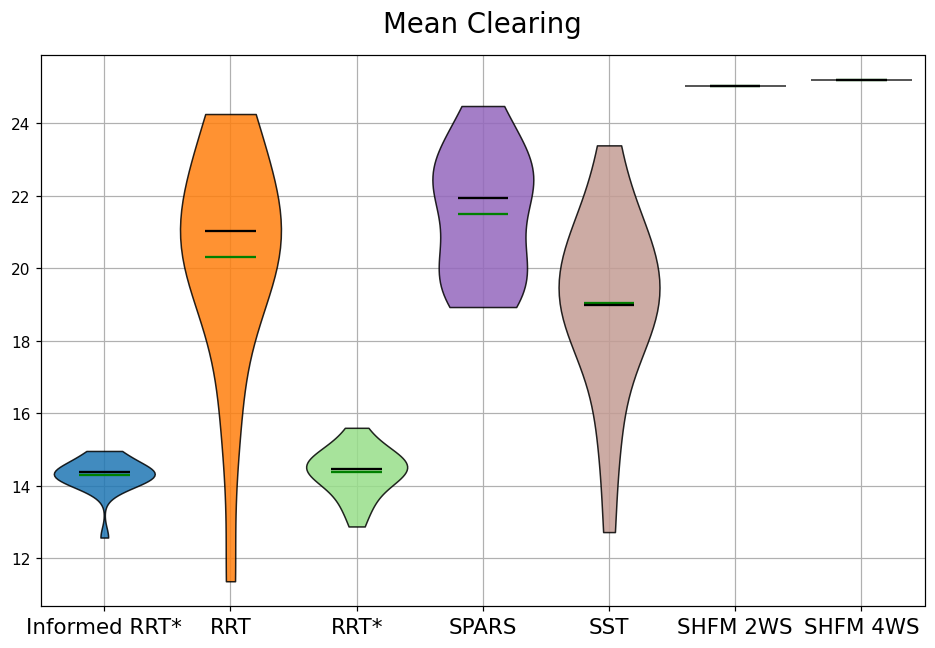

Saved ../figures/08_two_rooms_max_curvature.pdf.
Saved ../figures/08_two_rooms_max_curvature_nolegend.pdf.


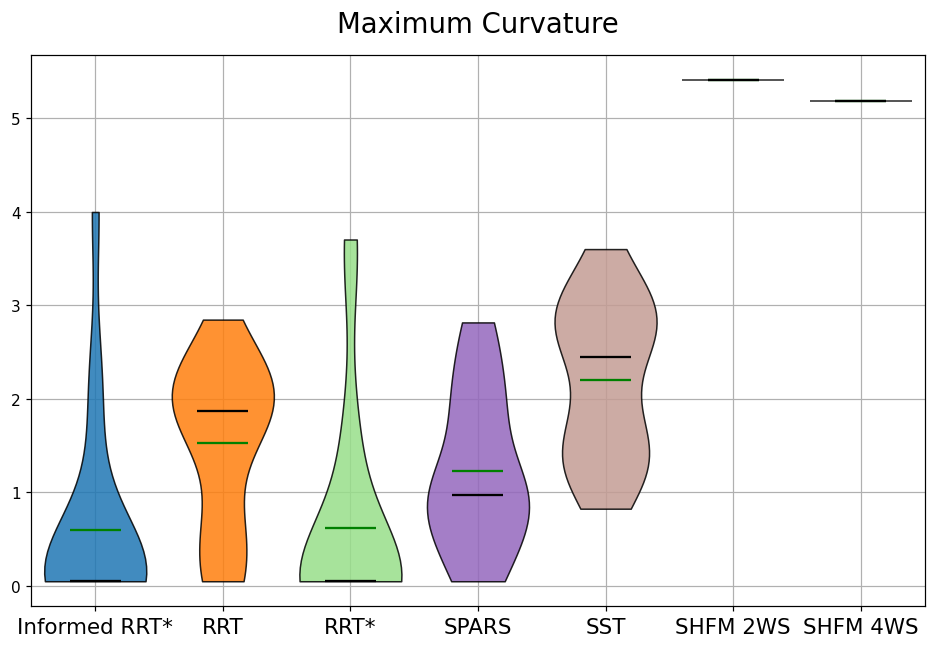

Saved ../figures/08_two_rooms_aol.pdf.
Saved ../figures/08_two_rooms_aol_nolegend.pdf.


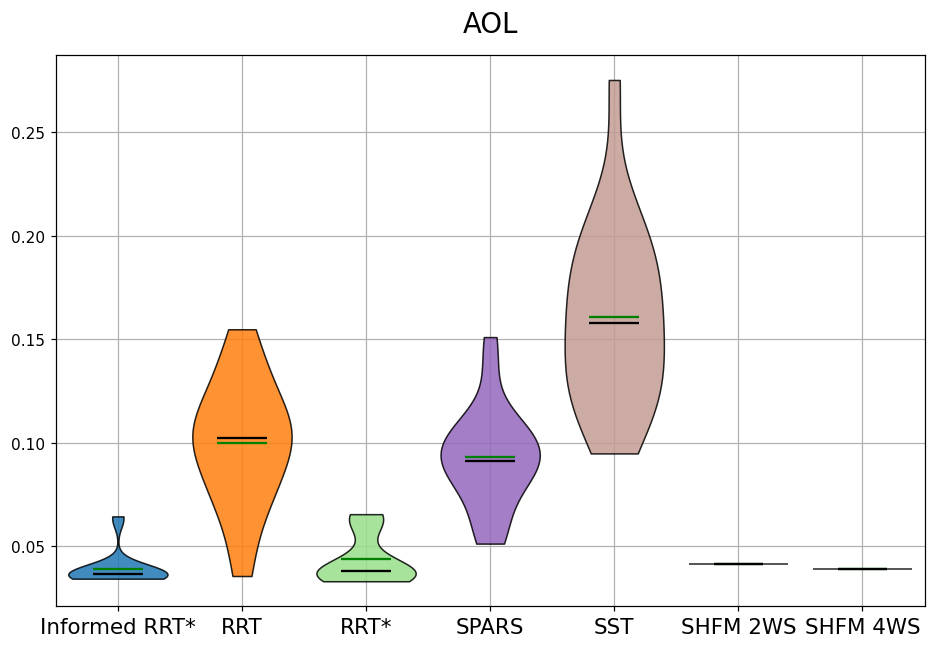

Saved ../figures/08_two_rooms_approach_heading_error.pdf.
Saved ../figures/08_two_rooms_approach_heading_error_nolegend.pdf.


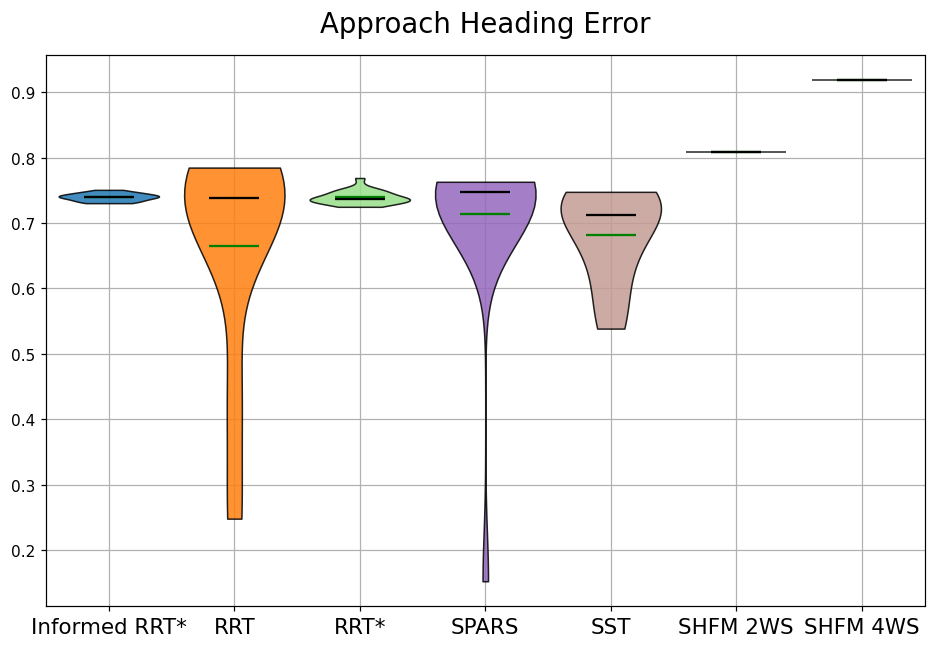

Saved ../figures/08_two_rooms_metrics.pdf.
Saved ../figures/08_two_rooms_metrics_nolegend.pdf.


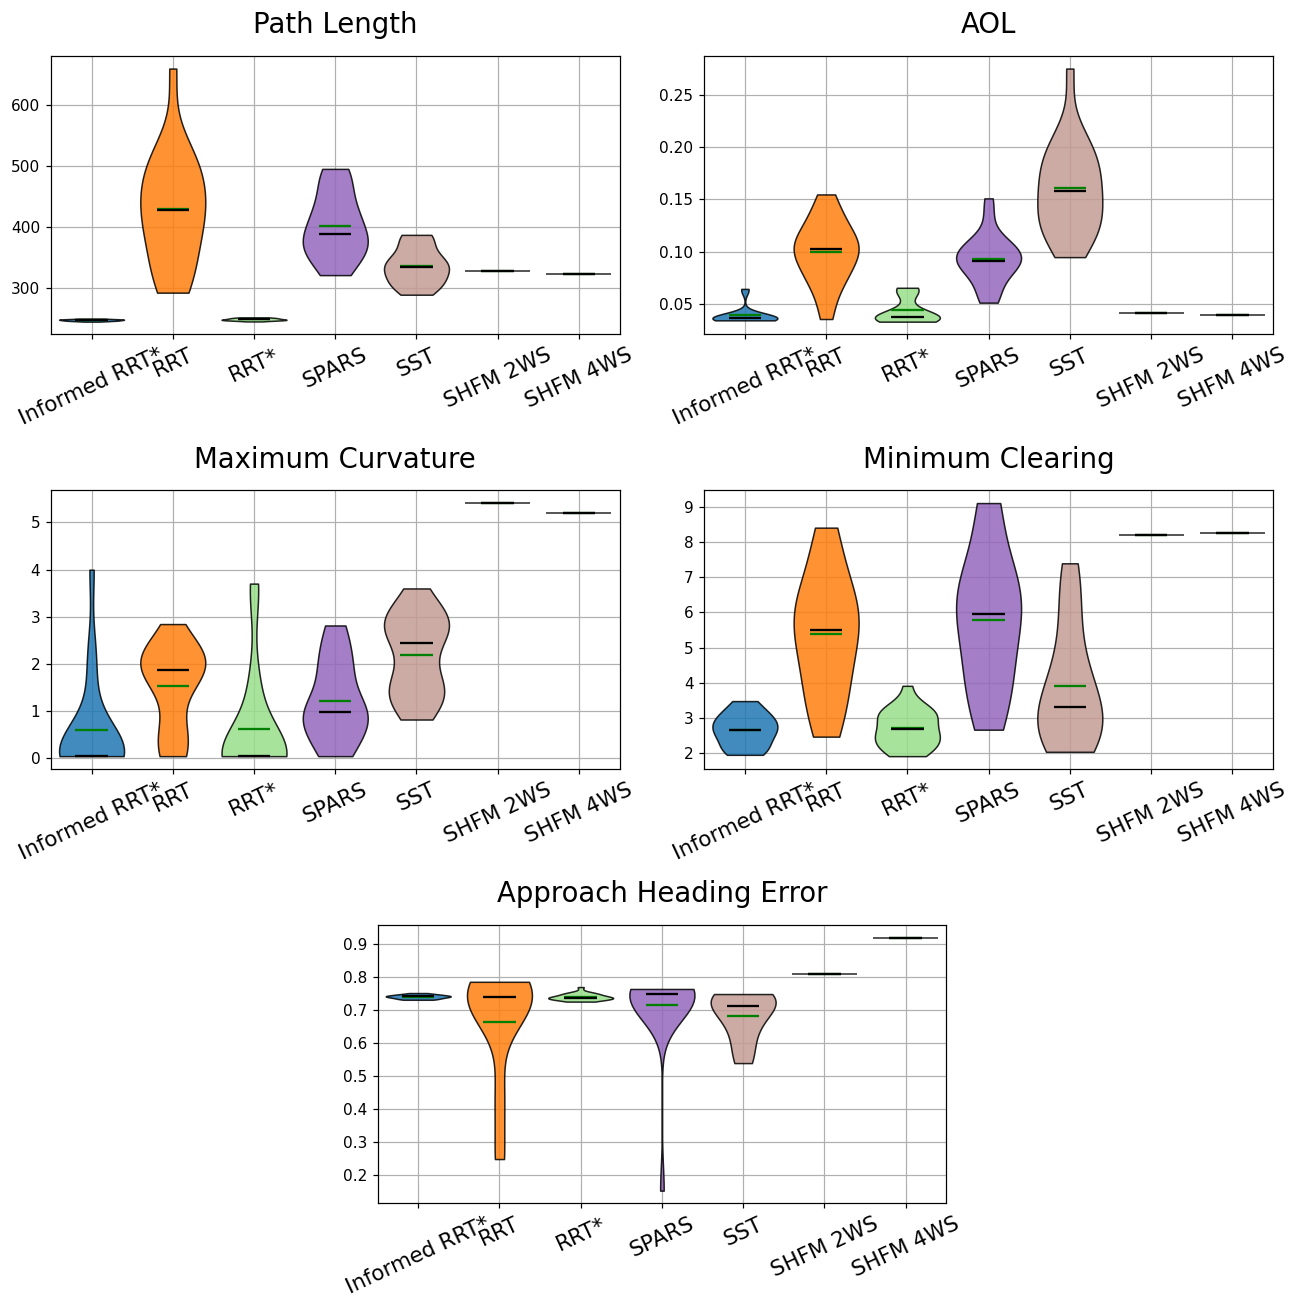

Saved ../figures/08_warehouse_path_length.pdf.
Saved ../figures/08_warehouse_path_length_nolegend.pdf.


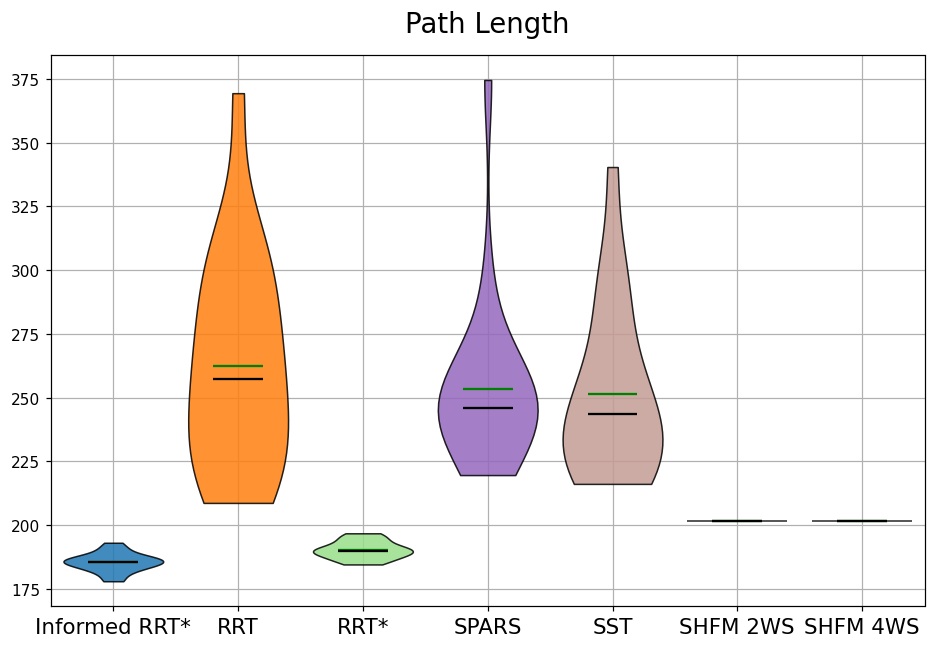

Saved ../figures/08_warehouse_min_clearing_distance.pdf.
Saved ../figures/08_warehouse_min_clearing_distance_nolegend.pdf.


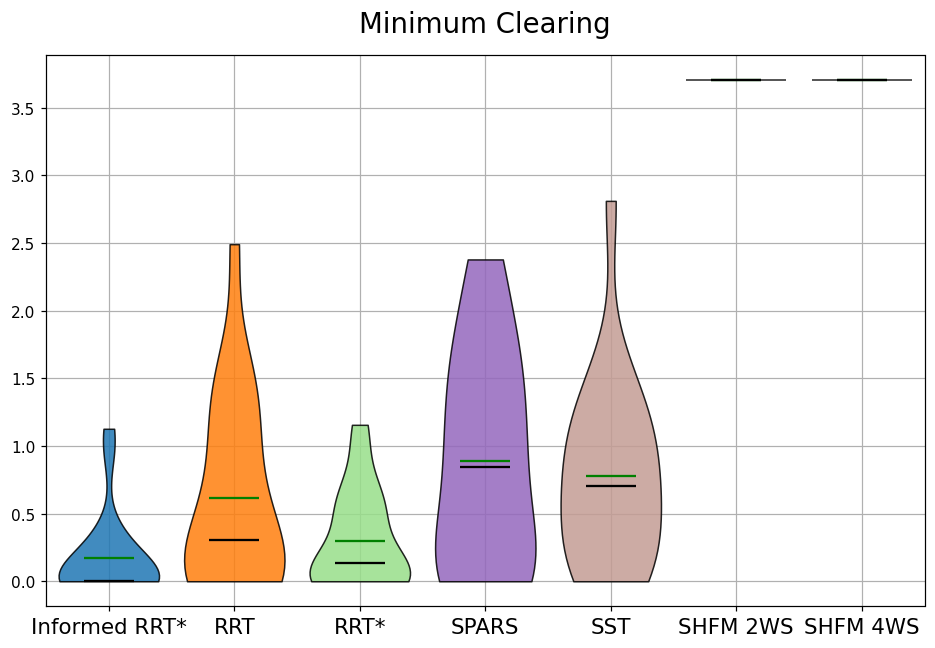

Saved ../figures/08_warehouse_mean_clearing_distance.pdf.
Saved ../figures/08_warehouse_mean_clearing_distance_nolegend.pdf.


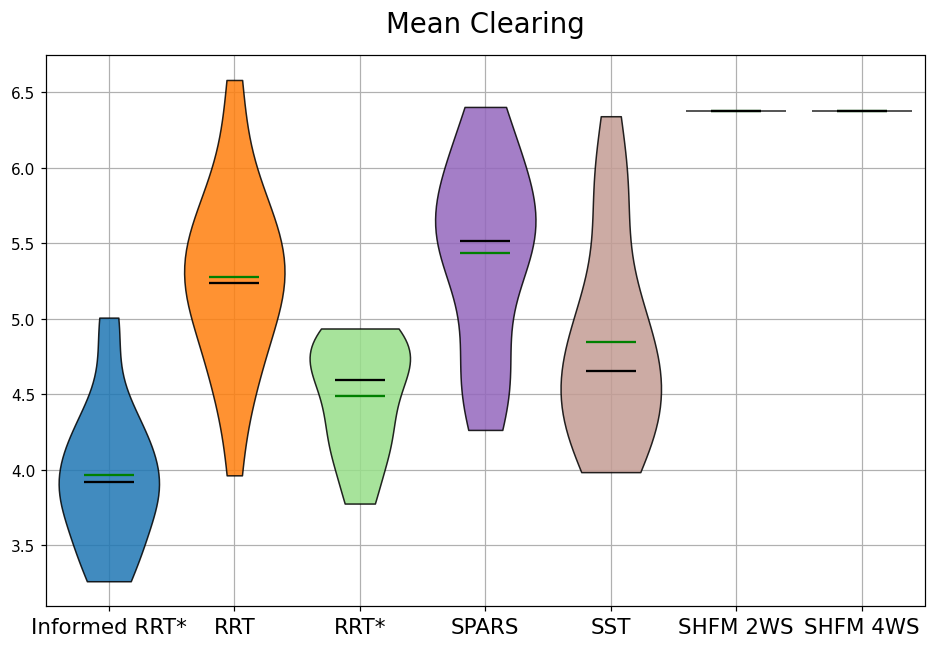

Saved ../figures/08_warehouse_max_curvature.pdf.
Saved ../figures/08_warehouse_max_curvature_nolegend.pdf.


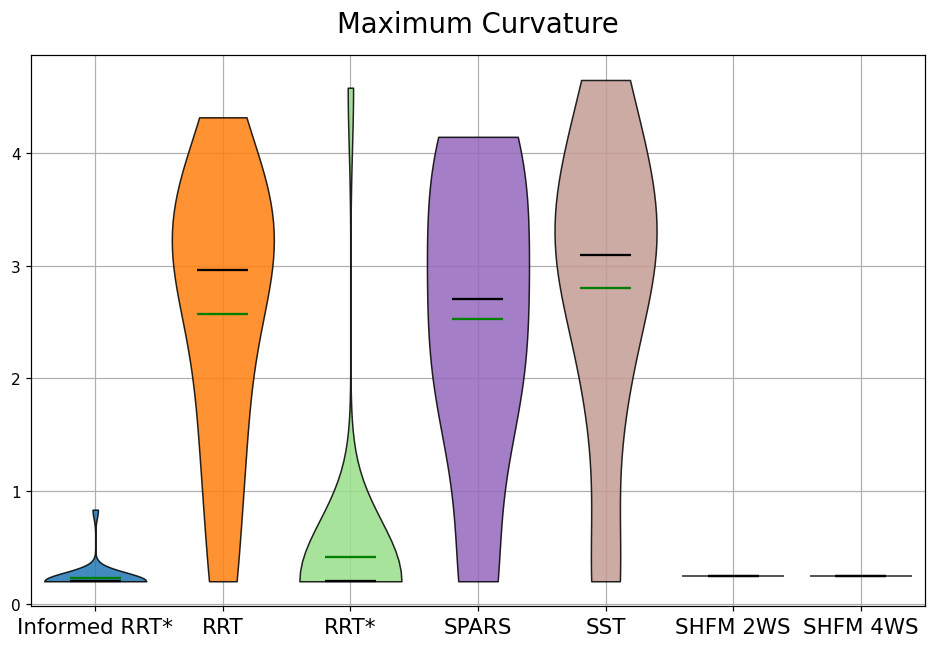

Saved ../figures/08_warehouse_aol.pdf.
Saved ../figures/08_warehouse_aol_nolegend.pdf.


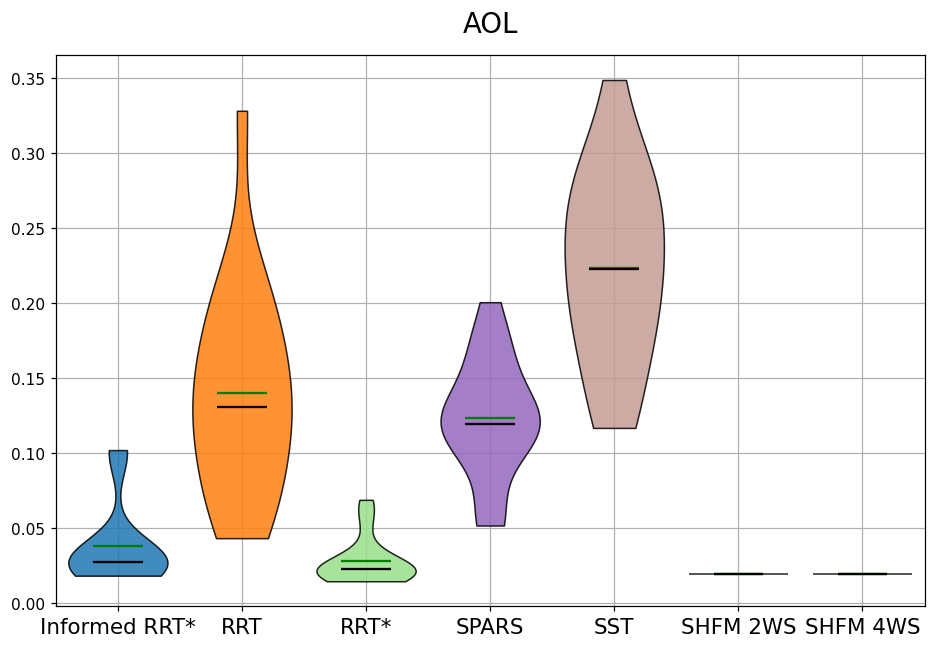

Saved ../figures/08_warehouse_approach_heading_error.pdf.
Saved ../figures/08_warehouse_approach_heading_error_nolegend.pdf.


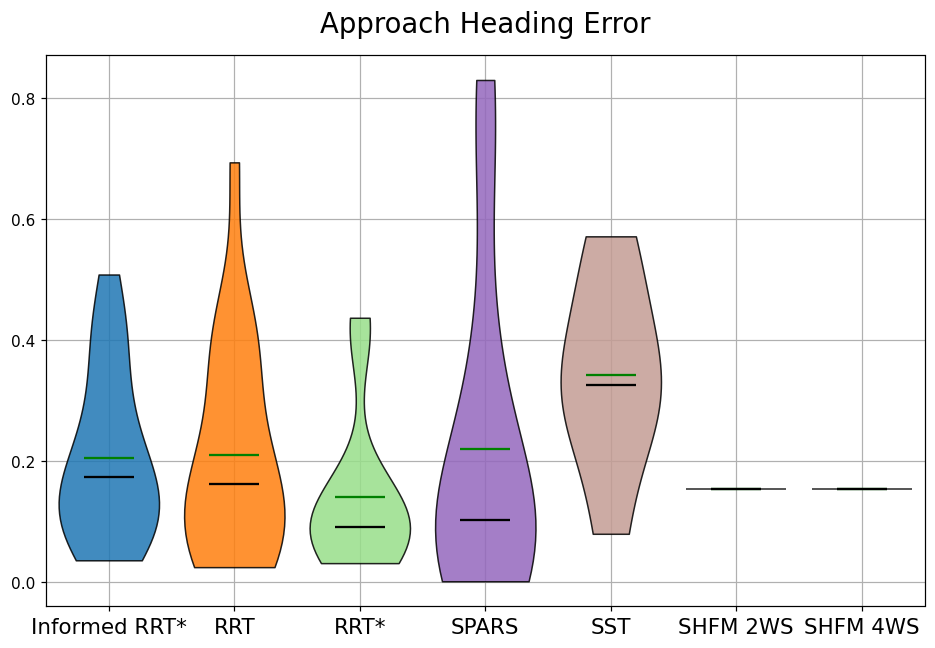

Saved ../figures/08_warehouse_metrics.pdf.
Saved ../figures/08_warehouse_metrics_nolegend.pdf.


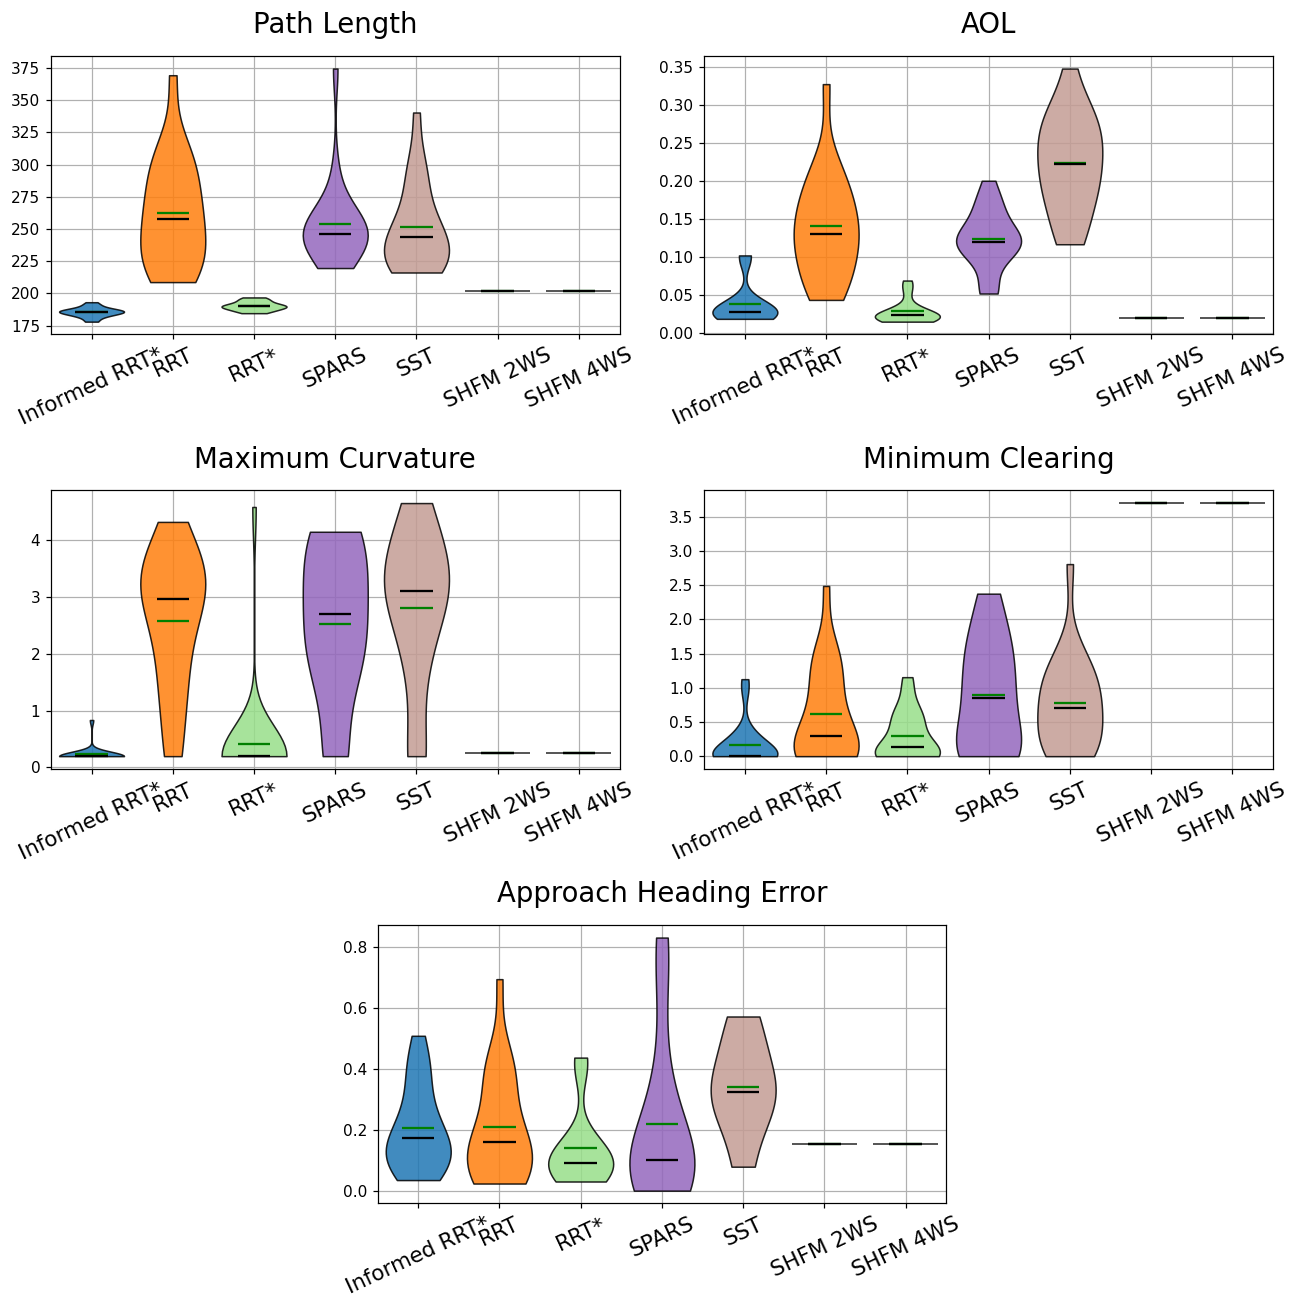

Saved ../figures/08_procedural_path_length.pdf.
Saved ../figures/08_procedural_path_length_nolegend.pdf.


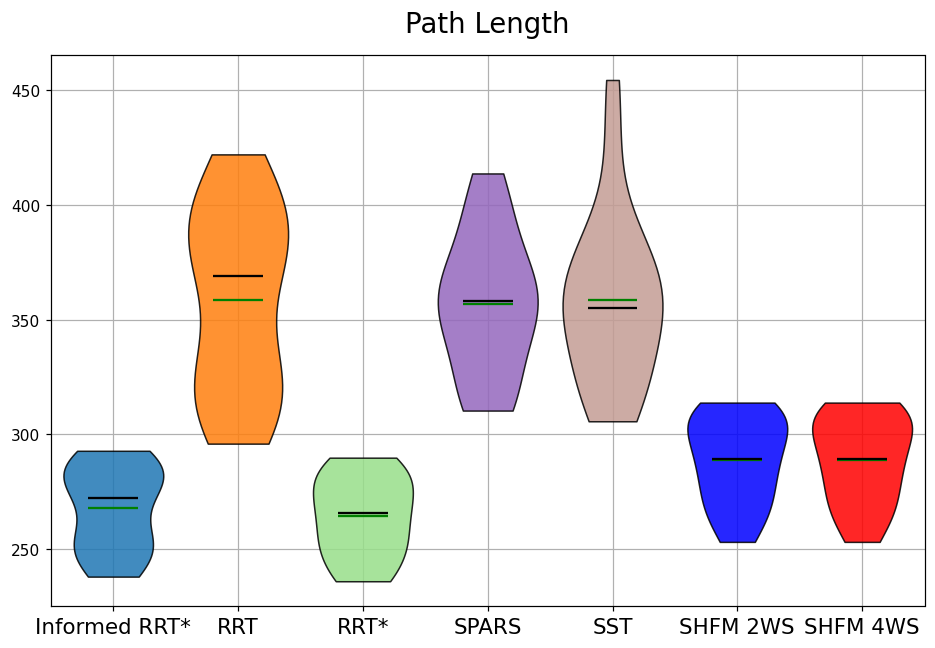

Saved ../figures/08_procedural_min_clearing_distance.pdf.
Saved ../figures/08_procedural_min_clearing_distance_nolegend.pdf.


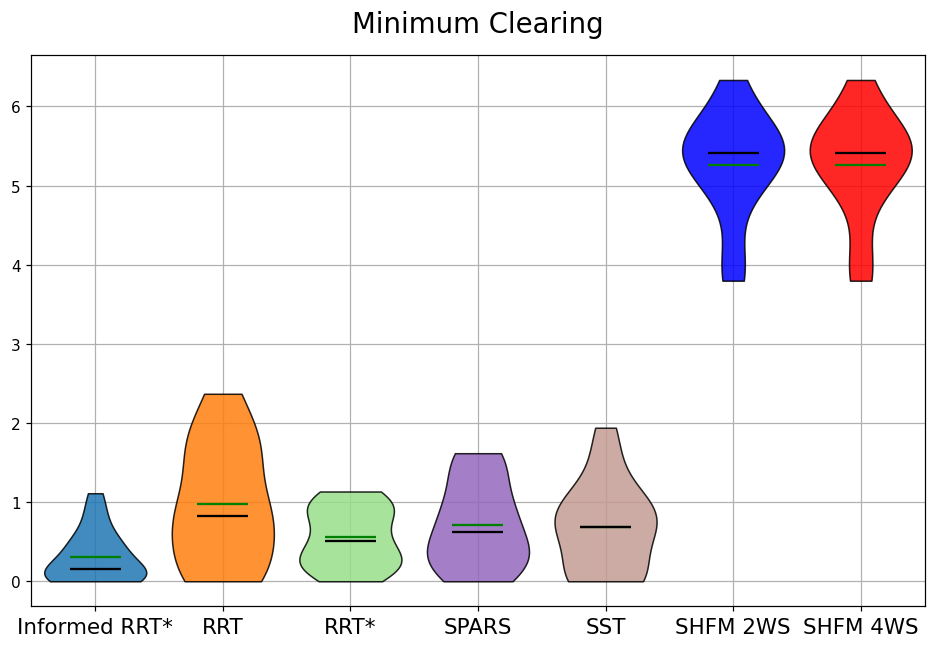

Saved ../figures/08_procedural_mean_clearing_distance.pdf.
Saved ../figures/08_procedural_mean_clearing_distance_nolegend.pdf.


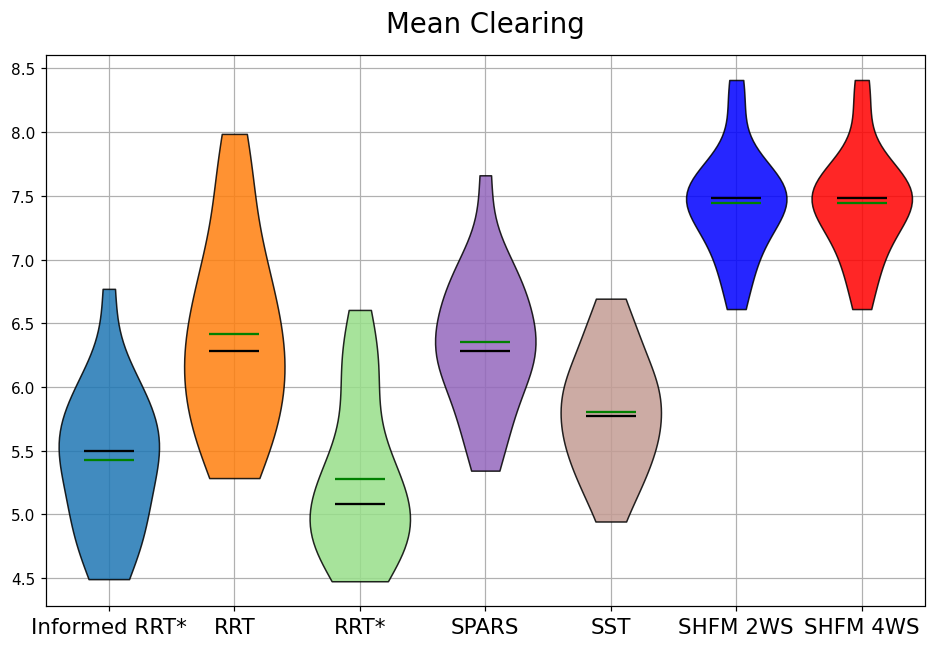

Saved ../figures/08_procedural_max_curvature.pdf.
Saved ../figures/08_procedural_max_curvature_nolegend.pdf.


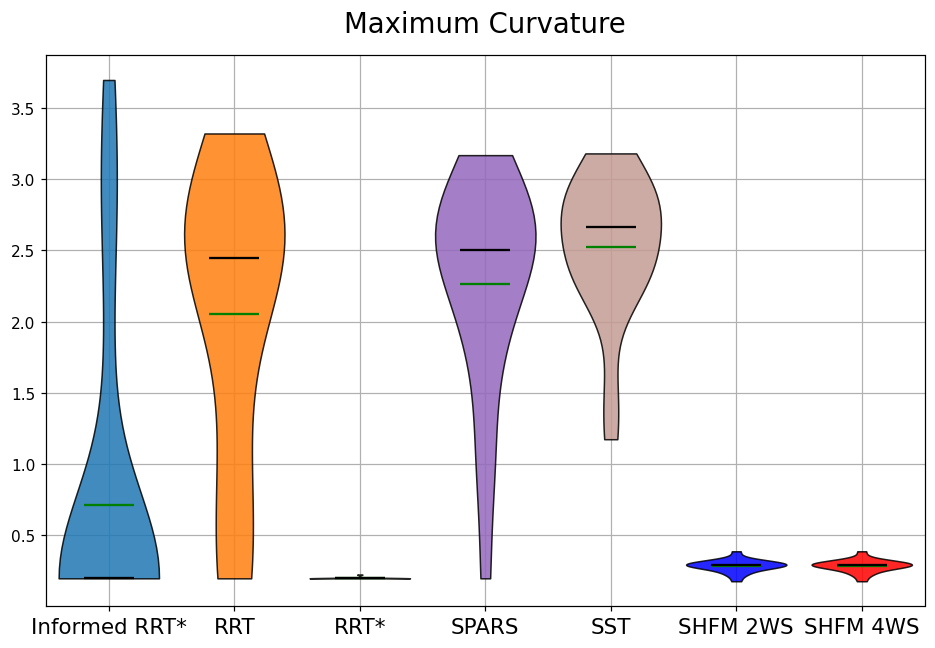

Saved ../figures/08_procedural_aol.pdf.
Saved ../figures/08_procedural_aol_nolegend.pdf.


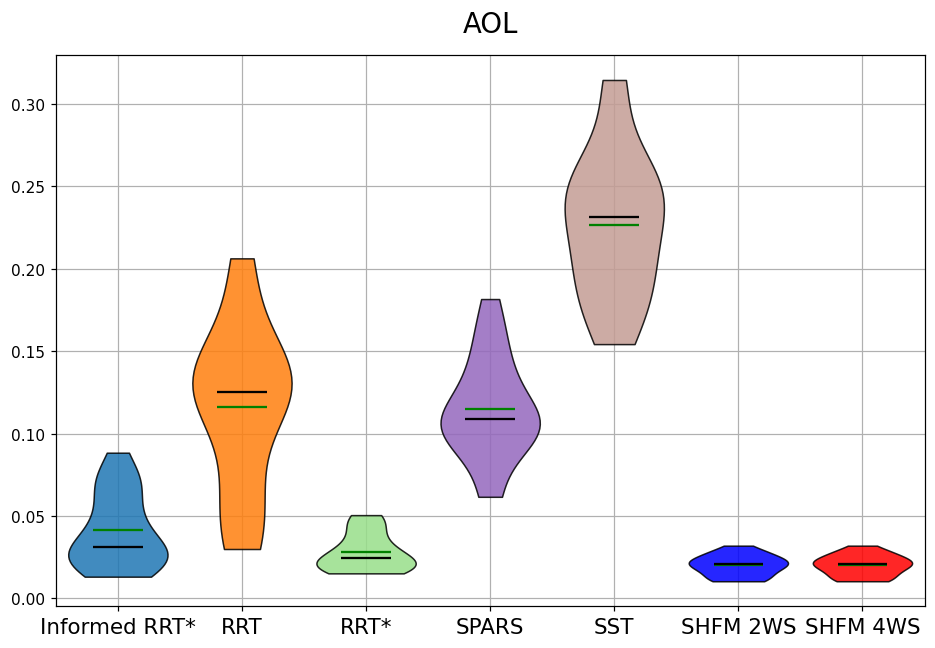

Saved ../figures/08_procedural_approach_heading_error.pdf.
Saved ../figures/08_procedural_approach_heading_error_nolegend.pdf.


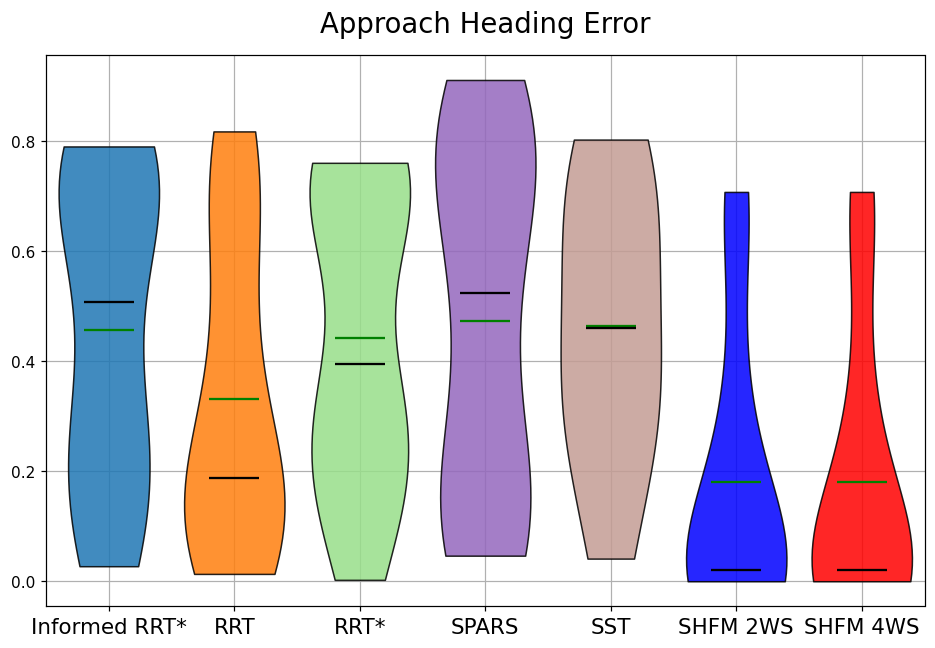

Saved ../figures/08_procedural_metrics.pdf.
Saved ../figures/08_procedural_metrics_nolegend.pdf.


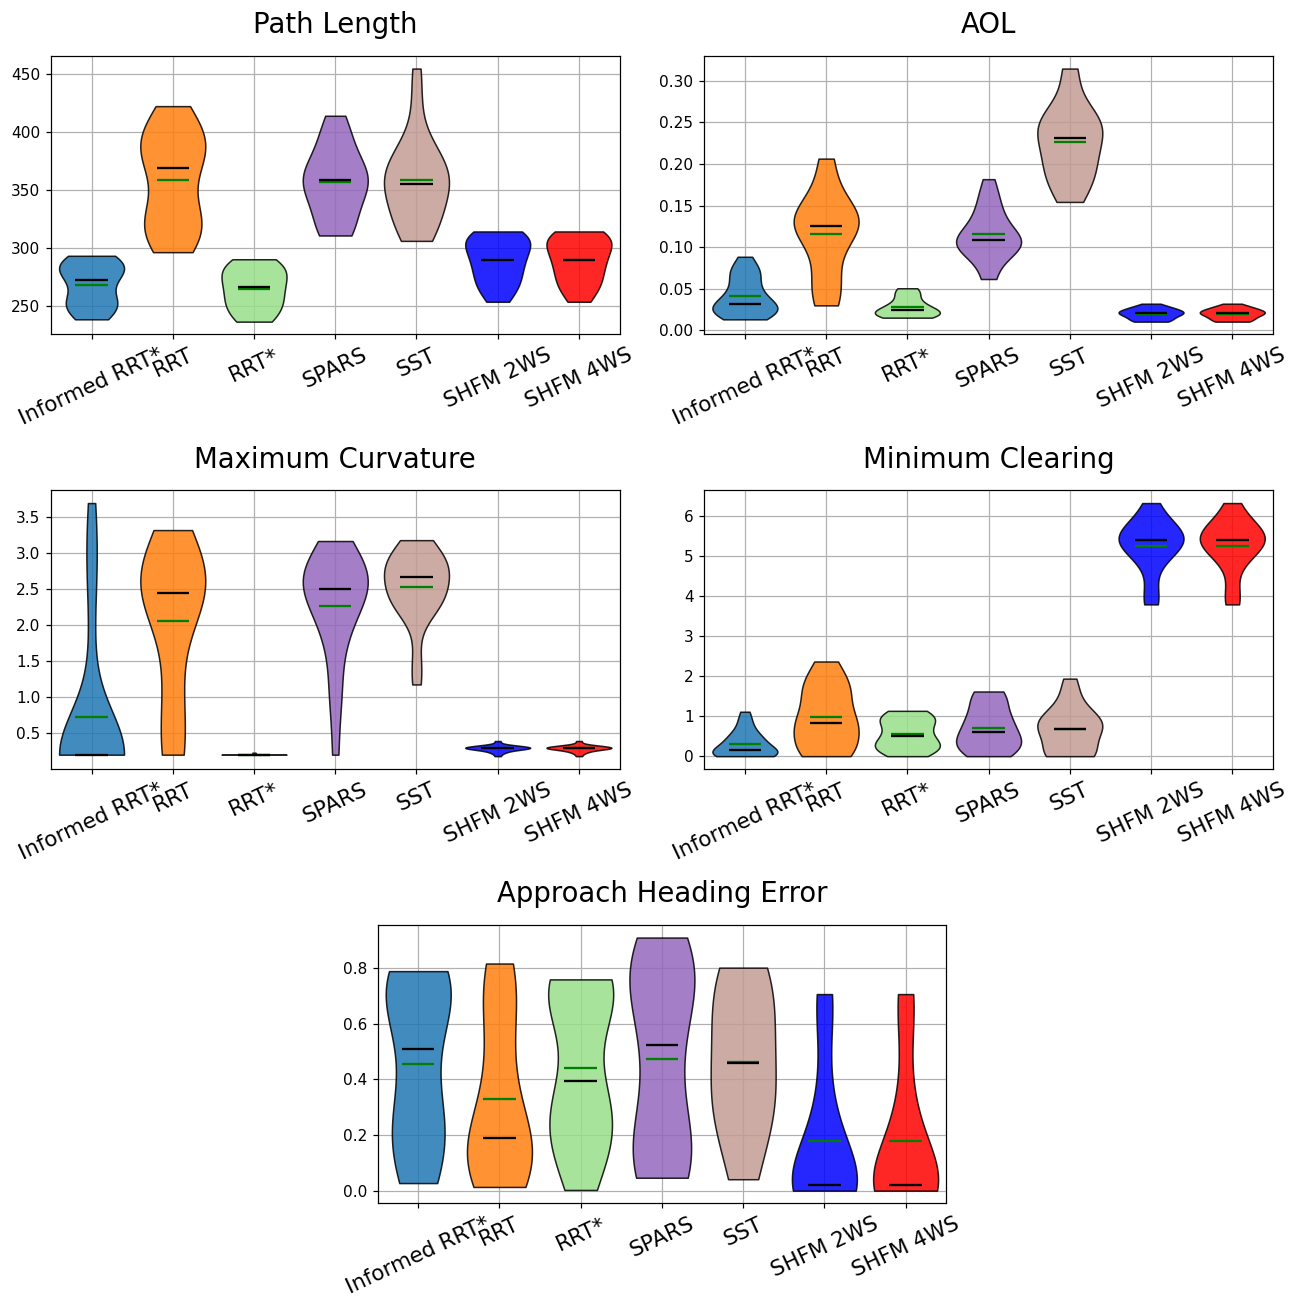

In [2]:
VIOLINS = ["path_length", "min_clearing_distance", "mean_clearing_distance",
           "max_curvature", "aol", "approach_heading_error"]
ZOOM = {"two_rooms": 8.0, "warehouse": 2.0, "procedural": 2.0}   # as in notebook 7

for name, R in RESULTS.items():
    for metric in VIOLINS:
        PL.metric_violin(R["file"], R["stats"], metric, zoom=ZOOM[name], silence=True,
                         save_file=os.path.join(FIGURE_DIR,
                                                "08_%s_%s.pdf" % (name, metric)))
    PL.metric_plate(R["file"], R["stats"], zoom=ZOOM[name], silence=True,
                    save_file=os.path.join(FIGURE_DIR, "08_%s_metrics.pdf" % name))

<a id='2'></a>
## 2. The table

We print the same metrics, with the normalised curvature of the sampling
planners measured again on their trajectories by the corrected metric. Runs
that never reached the pose are counted and left out of the averages:
including them would average a path to the goal with a path to another pose.
Our averages are over the runs of the campaign, one path per distinct problem.

In [3]:
METRICS = ["path_length", "min_clearing_distance", "mean_clearing_distance",
           "max_curvature", "normalized_curvature", "aol", "approach_heading_error"]
SHORT = {"path_length": "length", "min_clearing_distance": "clear.min",
         "mean_clearing_distance": "clear.mean", "max_curvature": "curv.max",
         "normalized_curvature": "curv.norm", "aol": "AOL",
         "approach_heading_error": "AHE"}

for name, R in RESULTS.items():
    print("\n=== %s ===" % name)
    rows, attempts = {}, {}
    for run in R["data"]["runs"]:
        for planner, plan in run["plans"].items():
            if plan is None:
                continue
            attempts[planner] = attempts.get(planner, 0) + 1
            if not B.reached_goal(plan):
                continue
            stats = dict(plan.get("stats") or {})
            if plan.get("trajectory"):
                with M.quiet():
                    stats["normalized_curvature"] = M.normalized_curvature(
                        np.asarray(plan["trajectory"], dtype=float)[:, :3])
            for m in METRICS:
                if stats.get(m) is not None:
                    rows.setdefault(planner, {}).setdefault(m, []).append(stats[m])
    for planner, stats in PL.campaign_ahe(R["file"], ZOOM[name]).items():
        rows.setdefault(planner, {}).update(stats)
    head = "%-16s%8s" % ("planner", "runs") + "".join("%12s" % SHORT[m] for m in METRICS)
    print(head); print("-" * len(head))
    for planner in sorted(attempts):
        v = rows.get(planner, {})
        print("%-16s%8s" % (planner, "%d/%d" % (len(v.get(METRICS[0], [])), attempts[planner]))
              + "".join("%12s" % ("--" if not v.get(m) else "%.2f" % np.mean(v[m]))
                        for m in METRICS))
    for planner in PL.OUR_PLANNERS:
        d = R["stats"][planner]
        print("%-16s%8d" % (planner, len(d["path_length"]))
              + "".join("%12.2f" % np.mean(d[m]) for m in METRICS))


=== two_rooms ===
planner             runs      length   clear.min  clear.mean    curv.max   curv.norm         AOL         AHE
------------------------------------------------------------------------------------------------------------
InformedRRTstar    20/20      247.65        2.68       14.29        0.59        4.84        0.04        0.74
RRT                20/20      429.40        5.39       20.31        1.53       14.30        0.10        0.66
RRTstar            20/20      248.82        2.71       14.38        0.62        4.68        0.04        0.74
SPARS              20/20      401.61        5.78       21.49        1.22       10.99        0.09        0.71
SST                10/20      329.73        3.12       18.48        1.58       14.55        0.16        0.68
SHFM_2WS              20      327.40        8.20       25.01        5.41        5.78        0.04        0.81
SHFM_4WS              20      323.62        8.24       25.19        5.19        6.20        0.04        0.92


<a id='3'></a>
## 3. Solve time and grid size

The anytime planners run to their budget, 15 s on Two-Rooms and on the
procedural maps and 5 s on Warehouse, so their solve time is that budget by
construction. This solver runs until the front has crossed the domain, so its
time depends on the grid. We solve Two-Rooms at four grid sizes, the scene
scaled with the grid so that the vehicle keeps its physical size, 4WS, at the
settings of notebook 7, with the goal heading set to 2.0 rad.

The times depend on the machine that runs this notebook: the GPU, its clock and
the other jobs on it for the solve, the CPU for the lift, which builds the
configuration space once per map. The first solve of a process also loads the
CUDA context and compiles the kernels, so one untimed solve precedes the
others. The last column is what the memory pool of cupy holds after the solve,
measured from an emptied pool.

In [4]:
import cupy as cp
from shfm import from_image, Planner, REFERENCE_COEFFICIENTS

K1, K2 = 2.0, 3.0
PASTSEED = dict(geodesic_PastSeed_delay=128)
GRIDS = ((50, 50, 50), (100, 100, 100), (200, 200, 100), (200, 200, 200))
pool = cp.get_default_memory_pool()


def scene(nx, ny, nt):
    "Two-Rooms on an nx by ny grid with nt orientations; zoom 8 at 200 cells."
    frac = nx / 200.0
    env = from_image("../data/maps/two_rooms.png", (nx, ny), zoom=8 * frac,
                     n_theta=nt, name="scaling")
    return env, [130 * frac, 140 * frac, 0.0, 0], [160 * frac, 30 * frac, 2.0, 0]


def solve(env, seed, tip):
    return Planner(env, k1=K1, k2=K2, **REFERENCE_COEFFICIENTS).solve(
        seed, [tip], free_start_mode=True, **PASTSEED)


env, seed, tip = scene(*GRIDS[0])
r = solve(env, seed, tip)          # loads the context and the kernels; not timed
del r, env
pool.free_all_blocks()

print("%12s %10s %8s %8s %8s %8s" % ("grid", "points", "lift", "solve", "total", "MB"))
for nx, ny, nt in GRIDS:
    pool.free_all_blocks()
    t0 = time.perf_counter()
    env, seed, tip = scene(nx, ny, nt)
    lift = time.perf_counter() - t0
    base = pool.total_bytes()
    t0 = time.perf_counter()
    r = solve(env, seed, tip)
    seconds = time.perf_counter() - t0
    print("%4dx%3dx%3d %10d %8.2f %8.2f %8.2f %8.0f"
          % (nx, ny, nt, nx * ny * nt, lift, seconds, lift + seconds,
             (pool.total_bytes() - base) / 1e6))
    del r, env

        grid     points     lift    solve    total       MB
  50x 50x 50     125000     0.04     0.14     0.18       38
 100x100x100    1000000     0.30     0.56     0.86      272
 200x200x100    4000000     1.23     1.97     3.21      768
 200x200x200    8000000     2.56     3.69     6.25     2048


---

Previous: [7. Benchmarks](07_benchmarks.ipynb)
Next: [9. The scheme, step by step](09_scheme_step_by_step.ipynb)